In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')
# !tar -xvf './cifar100.tar'

#Step 1: Download a dataset and preview images


In [ ]:
# !tar -xvf './cifar100.tar'

# Step 2: Custom Data Loading

In [11]:
import os
import time
import glob
import torch
import shutil
import torchvision
import torch.nn as nn
from torch.nn import functional as F
import torchvision.transforms as transforms
from PIL import Image
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.utils.data import Subset
import random

config = {
    "data_path":"./cifar100",
    "batch_size":128,
    "val_ratio":0.1,
    "split_seed":42,
}

# Common CIFAR-100 training statistics, fixed for train/test.
RGB_MEAN = (0.5071, 0.4867, 0.4408)
RGB_STD = (0.2675, 0.2565, 0.2761)

class mydataset(Dataset):
    def __init__(self, data_dir, flag, transform):
        super(mydataset,self).__init__()
        self.root       = data_dir
        self.label      = flag
        self.transform  = transform
        self.normalize_rgb = transforms.Normalize(RGB_MEAN, RGB_STD)

        self.img_dir = os.path.join(self.root, self.label)
        self.img_names  = glob.glob(os.path.join(self.img_dir, '*.jpg'))

        self.tags = ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider', 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor', 'train', 'trout', 'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm']

    def RGB2Gradient(self, img:torch.tensor):
        """
        Converts an RGB image tensor to its gradient magnitude using Sobel operator.
        The output is replicated to 3 channels to match the input dimensions of the other branch.
        """
        
        # Define Sobel kernels
        sobel_kernel_x = torch.tensor([[-1., 0., 1.], 
                                       [-2., 0., 2.], 
                                       [-1., 0., 1.]], dtype=torch.float32).reshape((1, 1, 3, 3))
        sobel_kernel_y = torch.tensor([[-1., -2., -1.], 
                                       [ 0.,  0.,  0.], 
                                       [ 1.,  2.,  1.]], dtype=torch.float32).reshape((1, 1, 3, 3))

        sobel_kernel_x = sobel_kernel_x.to(img.device)
        sobel_kernel_y = sobel_kernel_y.to(img.device)

        # Convert to grayscale: [3, H, W] -> Output [1, H, W]
        # gray_img = img[0, :, :] * 0.2989 + img[1, :, :] * 0.5870 + img[2, :, :] * 0.1140
        # gray_img = gray_img.unsqueeze(0)
        gray_img = transforms.Grayscale(num_output_channels=1)(img)

        # Add batch dimension [1, H, W] -> [1, 1, H, W]
        gray_img_batch = gray_img.unsqueeze(0) 

        # [YOU NEED TO FILL] Apply Sobel filters
        # Use F.conv2d, gray_img_batch, and the Sobel kernels (sobel_kernel_x, sobel_kernel_y) 
        # to calculate the gradients in the x and y directions.
        grad_x = F.conv2d(gray_img_batch, sobel_kernel_x, padding=1)
        grad_y = F.conv2d(gray_img_batch, sobel_kernel_y, padding=1)
        
        # [YOU NEED TO FILL] Calculate gradient magnitude ---
        # Calculate the magnitude (G = sqrt(Gx^2 + Gy^2)) from grad_x and grad_y.
        # The result should be stored in a variable named 'magnitude'.
        magnitude = torch.sqrt(grad_x ** 2 + grad_y ** 2)

        # Normalize magnitude
        mag_min = magnitude.min()
        mag_max = magnitude.max()
        epsilon = 1e-6 # Avoid division by zero
        normalized_magnitude = (magnitude - mag_min) / (mag_max - mag_min + epsilon)
        
        # Replicate to 3 channels [1, 1, H, W] -> [1, 3, H, W]
        normalized_magnitude_3channel = normalized_magnitude.repeat(1, 3, 1, 1)

        # Remove batch dimension [1, 3, H, W] -> [3, H, W]
        return normalized_magnitude_3channel.squeeze(0)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]

        img = Image.open(img_name).convert('RGB')
        img = self.transform(img)

        # Extract the class name from the filename only,
        # rather than searching the entire file path.
        filename = os.path.basename(img_name)

        # Example: aquarium_fish_0001.jpg -> aquarium_fish
        class_name = filename.rsplit('_', 1)[0]

        if class_name not in self.tags:
            raise ValueError(f"Unable to identify the image class: {filename}")

        tag = self.tags.index(class_name)

        # return img, tag
        # Calculate gradients before normalizing the RGB image.
        imgGradient = self.RGB2Gradient(img)
        return self.normalize_rgb(img), imgGradient, tag

    def __len__(self):
        return len(self.img_names)

# transform_train = transforms.Compose(
#         [transforms.Resize([64, 64]),
#          transforms.ToTensor()])
# Augment at native 32x32 resolution; compute gradients from the same transformed image.
transform_train = transforms.Compose(
        [transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
         transforms.RandomHorizontalFlip(p=0.5),
         transforms.Resize([64, 64]),
         transforms.ToTensor()])
transform_test = transforms.Compose(
    [transforms.Resize([64, 64]),
      transforms.ToTensor()])

train_dataset = mydataset(data_dir=config['data_path'], flag= "train", transform=transform_train)
test_dataset  = mydataset(data_dir=config['data_path'], flag= "test", transform=transform_test)

# Split the training files by class; use deterministic transforms for validation.
train_source = train_dataset
val_source = mydataset(data_dir=config['data_path'], flag="train", transform=transform_test)
train_source.img_names.sort()
val_source.img_names = train_source.img_names

class_indices = {}
for index, filename in enumerate(train_source.img_names):
    class_name = os.path.basename(filename).rsplit('_', 1)[0]
    class_indices.setdefault(class_name, []).append(index)

rng = random.Random(config['split_seed'])
train_indices, val_indices = [], []
for indices in class_indices.values():
    assert len(indices) >= 2, "Each class needs training and validation samples"
    rng.shuffle(indices)
    val_count = max(1, min(len(indices) - 1, int(len(indices) * config['val_ratio'])))
    val_indices.extend(indices[:val_count])
    train_indices.extend(indices[val_count:])

assert set(train_indices).isdisjoint(val_indices)
assert len(train_indices) + len(val_indices) == len(train_source)
train_dataset = Subset(train_source, train_indices)
val_dataset = Subset(val_source, val_indices)
split_info = {
    'seed': config['split_seed'],
    'val_ratio': config['val_ratio'],
    'train_indices': train_indices,
    'val_indices': val_indices,
}

# define data loader
train_loader = DataLoader(
        train_dataset,
        batch_size=config['batch_size'], shuffle=True, num_workers=4, pin_memory=True, drop_last=False)

test_loader = DataLoader(
        test_dataset,
        batch_size=config['batch_size'], shuffle=False, num_workers=4, pin_memory=True, drop_last=False)

val_loader = DataLoader(
        val_dataset,
        batch_size=config['batch_size'], shuffle=False, num_workers=4, pin_memory=True, drop_last=False)

print('train={}, val={}, test={}'.format(len(train_dataset), len(val_dataset), len(test_dataset)))


train=45000, val=5000, test=10000


# Step 3: Configure the Neural Network

In [12]:
import torch.nn as nn
from torch.nn import functional as F
from torch.nn import Sequential as Seq

class CommonBlock(nn.Module):
    def __init__(self, in_channel, out_channel, stride):        # 普通Block简单完成两次卷积操作
        super(CommonBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channel, out_channel, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channel)
        self.conv2 = nn.Conv2d(out_channel, out_channel, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channel)

    def forward(self, x):
        identity = x                                            # 普通Block的shortcut为直连，不需要升维下采样

        x = F.relu(self.bn1(self.conv1(x)), inplace=True)       # 完成一次卷积
        x = self.bn2(self.conv2(x))                             # 第二次卷积不加relu激活函数

        x += identity                                           # 两路相加
        return F.relu(x, inplace=True)                          # 添加激活函数输出

class SpecialBlock(nn.Module):                                  # 特殊Block完成两次卷积操作，以及一次升维下采样
    def __init__(self, in_channel, out_channel, stride):        # 注意这里的stride传入一个数组，shortcut和残差部分stride不同
        super(SpecialBlock, self).__init__()
        self.change_channel = nn.Sequential(                    # 负责升维下采样的卷积网络change_channel
            nn.Conv2d(in_channel, out_channel, kernel_size=1, stride=stride[0], padding=0, bias=False),
            nn.BatchNorm2d(out_channel)
        )
        self.conv1 = nn.Conv2d(in_channel, out_channel, kernel_size=3, stride=stride[0], padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channel)
        self.conv2 = nn.Conv2d(out_channel, out_channel, kernel_size=3, stride=stride[1], padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channel)

    def forward(self, x):
        identity = self.change_channel(x)                       # 调用change_channel对输入修改，为后面相加做变换准备

        x = F.relu(self.bn1(self.conv1(x)), inplace=True)
        x = self.bn2(self.conv2(x))                             # 完成残差部分的卷积

        x += identity
        return F.relu(x, inplace=True)                          # 输出卷积单元

class ConvNet(nn.Module):
    def __init__(self, classes_num):
        super(ConvNet, self).__init__()
        self.prepare1 = nn.Sequential(           # 预处理==》[batch, 64, 56, 56]
            nn.Conv2d(3, 64, 7, 2, 3),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1)
        )
        self.prepare2 = nn.Sequential(           # 预处理==》[batch, 64, 56, 56]
            nn.Conv2d(3, 64, 7, 2, 3),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1)
        )
        self.layer1 = nn.Sequential(            # layer1有点特别，由于输入输出的channel均是64，故两个CommonBlock
            CommonBlock(64, 64, 1),
            CommonBlock(64, 64, 1)
        )
        self.layer2 = nn.Sequential(            # layer234类似，由于输入输出的channel不同，故一个SpecialBlock，一个CommonBlock
            SpecialBlock(64, 128, [2, 1]),
            CommonBlock(128, 128, 1)
        )
        self.layer3 = nn.Sequential(
            SpecialBlock(128, 256, [2, 1]),
            CommonBlock(256, 256, 1)
        )
        self.layer4 = nn.Sequential(
            SpecialBlock(256, 512, [2, 1]),
            CommonBlock(512, 512, 1)
        )
        self.head = Seq(nn.AdaptiveAvgPool2d(1),
                  nn.Flatten(start_dim=1),
                  nn.Linear(512, classes_num))
    def forward(self, x, y):
        x = self.prepare1(x) + self.prepare2(y)         # 预处理
        
        x = self.layer1(x)          # 四个卷积单元
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.head(x)

        return x

class CrossAttention(nn.Module):
    """Bidirectional RGB/gradient attention followed by residual feature fusion."""
    def __init__(self, channels, num_heads=4):
        super().__init__()
        self.rgb_norm = nn.LayerNorm(channels)
        self.gradient_norm = nn.LayerNorm(channels)
        self.rgb_attention = nn.MultiheadAttention(channels, num_heads, batch_first=True)
        self.gradient_attention = nn.MultiheadAttention(channels, num_heads, batch_first=True)

    def forward(self, rgb, gradient):
        if rgb.ndim != 4 or rgb.shape != gradient.shape:
            raise ValueError("CrossAttention expects equally shaped [B, C, H, W] features")
        batch, channels, height, width = rgb.shape
        # Each spatial position is a token: [B, C, H, W] -> [B, H*W, C].
        rgb_tokens = rgb.flatten(2).transpose(1, 2)
        gradient_tokens = gradient.flatten(2).transpose(1, 2)
        rgb_norm = self.rgb_norm(rgb_tokens)
        gradient_norm = self.gradient_norm(gradient_tokens)

        # RGB queries gradient keys/values; gradient queries RGB keys/values.
        rgb_update, _ = self.rgb_attention(
            rgb_norm, gradient_norm, gradient_norm, need_weights=False)
        gradient_update, _ = self.gradient_attention(
            gradient_norm, rgb_norm, rgb_norm, need_weights=False)
        fused = (rgb_tokens + rgb_update + gradient_tokens + gradient_update) / 2
        return fused.transpose(1, 2).reshape(batch, channels, height, width)

# Q1: 简单双路+融合
class DualConvNet(nn.Module):
    def __init__(self, classes_num, dropout_p=0.0):
        super(DualConvNet, self).__init__()
        self.dropout_p = dropout_p
        self.prepare = nn.Sequential(           # [B, 3, 64, 64] -> [B, 64, 16, 16]
            nn.Conv2d(3, 64, 7, 2, 3),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1)
        )
        self.layer1 = nn.Sequential(            # layer1有点特别，由于输入输出的channel均是64，故两个CommonBlock
            CommonBlock(64, 64, 1),
            CommonBlock(64, 64, 1)
        )
        self.layer2 = nn.Sequential(            # layer234类似，由于输入输出的channel不同，故一个SpecialBlock，一个CommonBlock
            SpecialBlock(64, 128, [2, 1]),
            CommonBlock(128, 128, 1)
        )
        self.layer3 = nn.Sequential(
            SpecialBlock(128, 256, [2, 1]),
            CommonBlock(256, 256, 1)
        )

        self.prepareRGB = nn.Sequential(           # [B, 3, 64, 64] -> [B, 64, 16, 16]
            nn.Conv2d(3, 64, 7, 2, 3),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1)
        )
        self.layerRGB1 = nn.Sequential(            # layer1有点特别，由于输入输出的channel均是64，故两个CommonBlock
            CommonBlock(64, 64, 1),
            CommonBlock(64, 64, 1)
        )
        self.layerRGB2 = nn.Sequential(            # layer234类似，由于输入输出的channel不同，故一个SpecialBlock，一个CommonBlock
            SpecialBlock(64, 128, [2, 1]),
            CommonBlock(128, 128, 1)
        )
        self.layerRGB3 = nn.Sequential(
            SpecialBlock(128, 256, [2, 1]),
            CommonBlock(256, 256, 1)
        )

        # add cross_attention: layer3 outputs [B, 256, 4, 4] for 64x64 inputs.
        self.cross_attention = CrossAttention(channels=256, num_heads=4)
        
        self.layer4 = nn.Sequential(
            SpecialBlock(256, 512, [2, 1]),
            CommonBlock(512, 512, 1)
        )

        
        self.head = Seq(nn.AdaptiveAvgPool2d(1),
                  nn.Flatten(start_dim=1),
                  nn.Dropout(p=dropout_p),
                  nn.Linear(512, classes_num))
    def forward(self, x, y):
        # x: original RGB image; y: its gradient magnitude image.
        x = self.prepareRGB(x)
        x = self.layerRGB1(x)
        x = self.layerRGB2(x)
        x = self.layerRGB3(x)

        y = self.prepare(y)
        y = self.layer1(y)
        y = self.layer2(y)
        y = self.layer3(y)

        # add cross_attention; the fused map keeps its 256 channels.
        x = self.cross_attention(x, y)
        x = self.layer4(x)
        return self.head(x)

# Q2: WRN 风格的双路CNN
class WRNDualConvNet(nn.Module):
    """WRN-style stage widths/depth; reuse the existing post-activation blocks."""
    def __init__(self, classes_num, blocks_per_stage=4):
        super(WRNDualConvNet, self).__init__()
        # Channel constants: change widths here; every dependent layer uses them.
        channel = 16
        channel1 = 32
        channel2 = 64
        channel3 = 128
        if blocks_per_stage < 1:
            raise ValueError("blocks_per_stage must be at least 1")

        # Gradient branch: 32x32 -> 32x32 -> 16x16 -> 8x8.
        self.prepare = nn.Sequential(
            nn.Conv2d(3, channel, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(channel),
            nn.ReLU(inplace=True)
        )
        self.layer1 = nn.Sequential(
            SpecialBlock(channel, channel1, [1, 1]),
            *[CommonBlock(channel1, channel1, 1) for _ in range(blocks_per_stage - 1)]
        )
        self.layer2 = nn.Sequential(
            SpecialBlock(channel1, channel2, [2, 1]),
            *[CommonBlock(channel2, channel2, 1) for _ in range(blocks_per_stage - 1)]
        )
        self.layer3 = nn.Sequential(
            SpecialBlock(channel2, channel3, [2, 1]),
            *[CommonBlock(channel3, channel3, 1) for _ in range(blocks_per_stage - 1)]
        )

        # RGB branch: same layout, separately constructed parameters.
        self.prepareRGB = nn.Sequential(
            nn.Conv2d(3, channel, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(channel),
            nn.ReLU(inplace=True)
        )
        self.layerRGB1 = nn.Sequential(
            SpecialBlock(channel, channel1, [1, 1]),
            *[CommonBlock(channel1, channel1, 1) for _ in range(blocks_per_stage - 1)]
        )
        self.layerRGB2 = nn.Sequential(
            SpecialBlock(channel1, channel2, [2, 1]),
            *[CommonBlock(channel2, channel2, 1) for _ in range(blocks_per_stage - 1)]
        )
        self.layerRGB3 = nn.Sequential(
            SpecialBlock(channel2, channel3, [2, 1]),
            *[CommonBlock(channel3, channel3, 1) for _ in range(blocks_per_stage - 1)]
        )

        # Fuse at [B, channel3, 8, 8], then pool and classify directly.
        self.cross_attention = CrossAttention(channels=channel3, num_heads=4)
        self.head = Seq(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(start_dim=1),
            nn.Linear(channel3, classes_num)
        )

    def forward(self, x, y):
        # x: original RGB image; y: its gradient magnitude image.
        x = self.prepareRGB(x)
        x = self.layerRGB1(x)
        x = self.layerRGB2(x)
        x = self.layerRGB3(x)

        y = self.prepare(y)
        y = self.layer1(y)
        y = self.layer2(y)
        y = self.layer3(y)

        x = self.cross_attention(x, y)
        return self.head(x)


config = {
    "lr":1e-2,
    "momentum":0.9,
    "weight_decay":1e-4,
    "dropout_p": 0.5,  # Compare 0.0 and 0.2 in the four-group experiment.
}

device = torch.device("cuda:4" if torch.cuda.is_available() else "cpu")
print(device)
net = DualConvNet(classes_num=100, dropout_p=config["dropout_p"]).to(device)
print(f"{type(net).__name__}: {sum(p.numel() for p in net.parameters()):,} parameters")
criterion = torch.nn.CrossEntropyLoss().to(device)
optimizer = torch.optim.SGD(net.parameters(), lr=config["lr"], momentum=config["momentum"], weight_decay=config["weight_decay"])

cuda:4
DualConvNet: 14,538,084 parameters


# Step 4: Train the network and save model

In [ ]:
import time

class AverageMeter(object):
    def __init__(self):
      self.reset()

    def reset(self):
      self.val   = 0
      self.avg   = 0
      self.sum   = 0
      self.count = 0

    def update(self, val, n=1):
      self.val   = val
      self.sum   += val * n
      self.count += n
      self.avg   = self.sum / self.count

def accuracy(output, target, topk=(1,1)):
    """Computes the precision@k for the specified values of k"""
    maxk = max(topk)
    batch_size = target.size(0)

    _, pred = output.topk(maxk, 1, True, True)
    pred    = pred.t()
    correct = pred.eq(target.view(1, -1).expand_as(pred))

    res = []
    for k in topk:
      correct_k = correct[:k].view(-1).float().sum(0)
      res.append(correct_k.mul_(100.0 / batch_size))
    return res[0]

def train(train_loader, net, optimizer, criterion, epoch):
    batch_time = AverageMeter()
    data_time  = AverageMeter()
    top1       = AverageMeter()

    LOSS = AverageMeter()

    net.train()

    end = time.time()
    # for i, (img, target) in enumerate(train_loader, start=1):
    for i, (img, imgGradient, target) in enumerate(train_loader, start=1):
        data_time.update(time.time() - end)

        img = img.to(device)
        imgGradient = imgGradient.to(device)
        target = target.to(device)

        # out = net(img)
        out = net(img, imgGradient)

        loss = criterion(out, target)

        prec1 = accuracy(out, target) # prec1:list
        top1.update(prec1.item(), img.size(0))

        LOSS.update(loss.item(), img.size(0))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_time.update(time.time() - end)
        end = time.time()

        if i % 50 == 1:
            log_str = ('Epoch[{0}]:[{1:03}/{2:03}] '
                       'Time:{batch_time.val:.4f} '
                       'Data:{data_time.val:.4f}  '
                       'loss:{loss.val:.4f}({loss.avg:.4f})  '
                       'prec@1:{top1.val:.2f}({top1.avg:.2f})  '.format(
                       epoch, i, len(train_loader), batch_time=batch_time, data_time=data_time,
                       loss=LOSS,
                       top1=top1))
            print(log_str)

    return LOSS.avg

@torch.no_grad()
def validate(val_loader, net, criterion):
    losses = AverageMeter()
    top1   = AverageMeter()

    net.eval()

    for img, imgGradient, target in val_loader:
        img = img.to(device)
        imgGradient = imgGradient.to(device)
        target = target.to(device)

        out = net(img, imgGradient)
        loss = criterion(out, target)
        prec1 = accuracy(out, target)
        losses.update(loss.item(), img.size(0))
        top1.update(prec1.item(), img.size(0))

    print('Validation Loss: {:.4f}, Prec@1: {:.2f}%'.format(losses.avg, top1.avg))
    return losses.avg, top1.avg


def save_checkpoint(state, is_best, save_root, epoch):
    if not os.path.exists(save_root):
        os.makedirs(save_root)
    save_path = os.path.join(save_root, 'epoch_{}.pth.tar'.format(str(epoch)))
    # torch.save(state, save_path)
    # Replace the checkpoint only after writing succeeds.
    torch.save(state, save_path + '.tmp')
    os.replace(save_path + '.tmp', save_path)
    if is_best:
        best_save_path = os.path.join(save_root, 'model_best.pth.tar')
        # shutil.copyfile(save_path, best_save_path)
        shutil.copyfile(save_path, best_save_path + '.tmp')
        os.replace(best_save_path + '.tmp', best_save_path)

config = {
    # "save_root":"./result",
    # "save_root":"./result/verified_no_mixup",
    "save_root":"./result/verified_crop",
    "epochs":100,
}

# best_top1 = 0
best_top1 = -1.0  # Save the first epoch even if validation accuracy is zero.
best_epoch = 0
# test_top1 = 0
val_top1 = 0
for epoch in range(1, config["epochs"]+1):
    # train one epoch
    epoch_start_time = time.time()
    train_loss = train(train_loader, net, optimizer, criterion, epoch)

    # evaluate on testing set
    # test_top1 = test(test_loader, net, criterion)
    # Select the model using validation data only.
    val_loss, val_top1 = validate(val_loader, net, criterion)

    epoch_duration = time.time() - epoch_start_time
    print('Epoch time: {}s'.format(int(epoch_duration)))

    # save model
    # You can modify this section to save the best-performing model
    # and load the best model for testing after training is complete.
    # is_best = False
    is_best = val_top1 > best_top1
    # if test_top1 > best_top1:
    #     best_top1 = test_top1
    #     is_best = True
    if is_best:
        best_top1 = val_top1
        best_epoch = epoch
    print('Saving models......')
    save_checkpoint({
        'epoch': epoch,
        'net': net.state_dict(),
        # 'prec@1': test_top1,
        'prec@1': val_top1,  # Validation accuracy, not test accuracy.
        'val_loss': val_loss,
        'train_loss': train_loss,
        'best_top1': best_top1,
        'best_epoch': best_epoch,
        'optimizer': optimizer.state_dict(),
        'architecture': type(net).__name__,
        'dropout_p': getattr(net, 'dropout_p', 0.0),
        'split': split_info,
        # 'input_processing': {'rgb_mean': RGB_MEAN, 'rgb_std': RGB_STD, 'image_size': 64},
        'input_processing': {
            'rgb_mean': RGB_MEAN, 'rgb_std': RGB_STD, 'image_size': 64,
            'train_augmentation': str(transform_train),
        },
    }, is_best, config["save_root"], epoch)

# Use the best validation model for subsequent prediction and evaluation.
best_path = os.path.join(config["save_root"], 'model_best.pth.tar')
checkpoint = torch.load(best_path, map_location='cpu', weights_only=True)
assert checkpoint['architecture'] == type(net).__name__
net.load_state_dict(checkpoint['net'])
net.eval()
print('Loaded best model: epoch={}, val Prec@1={:.2f}%'.format(
    checkpoint['epoch'], checkpoint['prec@1']))


Epoch[1]:[001/352] Time:0.8025 Data:0.7269  loss:4.9051(4.9051)  prec@1:0.78(0.78)  
Epoch[1]:[051/352] Time:0.0161 Data:0.0001  loss:4.3339(4.5424)  prec@1:3.91(3.55)  
Epoch[1]:[101/352] Time:0.2318 Data:0.2213  loss:4.1249(4.3333)  prec@1:9.38(5.31)  
Epoch[1]:[151/352] Time:0.0179 Data:0.0002  loss:3.5924(4.1752)  prec@1:13.28(7.24)  
Epoch[1]:[201/352] Time:0.1529 Data:0.1418  loss:3.8242(4.0440)  prec@1:7.81(8.77)  
Epoch[1]:[251/352] Time:0.0880 Data:0.0767  loss:3.3343(3.9459)  prec@1:24.22(9.91)  
Epoch[1]:[301/352] Time:0.1095 Data:0.0966  loss:3.4935(3.8592)  prec@1:15.62(11.07)  
Epoch[1]:[351/352] Time:0.0923 Data:0.0823  loss:3.3640(3.7745)  prec@1:18.75(12.18)  
Validation Loss: 3.3863, Prec@1: 17.72%
Epoch time: 33s
Saving models......
Epoch[2]:[001/352] Time:0.3901 Data:0.3687  loss:3.4589(3.4589)  prec@1:15.62(15.62)  
Epoch[2]:[051/352] Time:0.0170 Data:0.0001  loss:2.9689(3.1435)  prec@1:21.88(21.58)  
Epoch[2]:[101/352] Time:0.2068 Data:0.1918  loss:2.9235(3.1226) 

# Step 5: Test on single image

In [14]:
# Reload the best validation model when running this cell again.
best_path = os.path.join(config["save_root"], 'model_best.pth.tar')
checkpoint = torch.load(best_path, map_location='cpu', weights_only=True)
assert checkpoint['architecture'] == type(net).__name__
net.load_state_dict(checkpoint['net'])
net.eval()

# img = Image.open("./cifar100/test/apple_9904.jpg")
with Image.open("./cifar100/test/apple_9904.jpg") as image:
    img = transform_test(image.convert('RGB'))
# img = transform_test(img).unsqueeze(0).to(device)
# Match __getitem__: raw RGB -> Sobel gradient -> RGB normalization.
imgGradient = test_dataset.RGB2Gradient(img)
img = test_dataset.normalize_rgb(img).unsqueeze(0).to(device)
imgGradient = imgGradient.unsqueeze(0).to(device)
# out = net(img)
with torch.no_grad():
    out = net(img, imgGradient)
predicted_classes = torch.argmax(out, dim=1)
tags = ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider', 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor', 'train', 'trout', 'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm']

# print(tags[predicted_classes[0]])
print(tags[predicted_classes[0].item()])

apple


# Step 6: Evaluate model accuracy

In [15]:
def test(test_loader, net, criterion):
    losses = AverageMeter()
    top1   = AverageMeter()

    net.eval()

    # for i, (img, target) in enumerate(test_loader, start=1):
    for i, (img, imgGradient, target) in enumerate(test_loader, start=1):
        img = img.to(device)
        imgGradient = imgGradient.to(device)
        target = target.to(device)

        with torch.no_grad():
            # out = net(img)
            out = net(img, imgGradient)
            loss = criterion(out, target)

        prec1 = accuracy(out, target) # prec1:list
        losses.update(loss.item(), img.size(0))
        top1.update(prec1.item(), img.size(0))

    f_l = [losses.avg, top1.avg]
    print('---------------------------------test classification result---------------------------------')
    print('Loss: {:.4f}, Prec@1: {:.2f}%'.format(*f_l))

    return top1.avg

# Evaluate the model selected by validation accuracy, including on cell reruns.
best_path = os.path.join(config["save_root"], 'model_best.pth.tar')
checkpoint = torch.load(best_path, map_location='cpu', weights_only=True)
assert checkpoint['architecture'] == type(net).__name__
net.load_state_dict(checkpoint['net'])
net.eval()
print('Loaded best model: epoch={}, val Prec@1={:.2f}%'.format(
    checkpoint['epoch'], checkpoint['prec@1']))

test_top1 = test(test_loader, net, criterion)

Loaded best model: epoch=93, val Prec@1=63.58%
---------------------------------test classification result---------------------------------
Loss: 2.0256, Prec@1: 62.95%


# Step 7: T-SNE Visualization

##Use hooks in PyTorch to extract feature representations from the intermediate layers of the model for the test set "testloader", and visualize them using the T-SNE method. The specific requirements are as follows:
####Visualize the features before and after the dual-branch feature fusion. If there are multiple fusions, you may choose specific layers for visualization.


In [1]:
# Q3: collect test-set features before and immediately after fusion.
from pathlib import Path
import os
import json
import time
import numpy as np

viz_checkpoint_path = Path("./result/verified_crop/model_best.pth.tar")
viz_output_dir = viz_checkpoint_path.parent / "tsne"
viz_output_dir.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(Path(".cache/matplotlib").resolve()))
visualization_seed = 42
viz_device = torch.device(device)
viz_layers = {
    "rgb_before": ("layerRGB3", "RGB before fusion"),
    "gradient_before": ("layer3", "Gradient before fusion"),
    "fused_after": ("cross_attention", "After cross-attention fusion"),
}


@torch.no_grad()
def collect_tsne_features(model, loader, target_device):
    """One forward pass per batch; hooks pool each feature map to [B, C]."""
    model.eval()
    batches = {name: [] for name in viz_layers}
    label_batches = []
    handles = []

    def make_hook(name):
        def record(module, inputs, output):
            batches[name].append(output.mean(dim=(2, 3)).detach().float().cpu().numpy())
        return record

    try:
        for name, (layer_name, _) in viz_layers.items():
            handles.append(getattr(model, layer_name).register_forward_hook(make_hook(name)))
        for batch_index, (rgb, gradient, targets) in enumerate(loader, start=1):
            model(rgb.to(target_device), gradient.to(target_device))
            label_batches.append(targets.cpu().numpy())
            if batch_index % 20 == 0 or batch_index == len(loader):
                print(f"Feature extraction: {batch_index}/{len(loader)} batches")
    finally:
        # Also remove hooks if inference fails or is interrupted.
        for handle in handles:
            handle.remove()

    labels = np.concatenate(label_batches)
    features = {name: np.concatenate(values, axis=0) for name, values in batches.items()}
    for name, values in features.items():
        assert values.shape == (len(labels), 256), (name, values.shape)
        assert np.isfinite(values).all(), f"Non-finite features: {name}"
    return features, labels


viz_checkpoint = torch.load(viz_checkpoint_path, map_location="cpu", weights_only=True)
if viz_checkpoint["architecture"] != "DualConvNet":
    raise ValueError("Step 7 expects a DualConvNet checkpoint")
processing = viz_checkpoint["input_processing"]
assert tuple(processing["rgb_mean"]) == RGB_MEAN
assert tuple(processing["rgb_std"]) == RGB_STD
assert processing["image_size"] == 64
assert test_dataset.transform is transform_test, "Use deterministic test preprocessing"
assert isinstance(test_loader.sampler, torch.utils.data.SequentialSampler)
assert not test_loader.drop_last, "Every test image must be included"
viz_metadata = {
    "checkpoint": str(viz_checkpoint_path.resolve()),
    "checkpoint_epoch": int(viz_checkpoint["epoch"]),
    "validation_accuracy": float(viz_checkpoint["prec@1"]),
    "dropout_p": float(viz_checkpoint["dropout_p"]),
    "input_processing": processing,
    "layers": {name: layer for name, (layer, _) in viz_layers.items()},
}
viz_net = DualConvNet(
    classes_num=len(test_dataset.tags), dropout_p=viz_metadata["dropout_p"])
viz_net.load_state_dict(viz_checkpoint["net"])
del viz_checkpoint
viz_net = viz_net.to(viz_device).eval()
print(f"Loaded epoch {viz_metadata['checkpoint_epoch']}, "
      f"val={viz_metadata['validation_accuracy']:.2f}%, device={viz_device}")

started = time.perf_counter()
viz_features, viz_labels = collect_tsne_features(viz_net, test_loader, viz_device)
assert len(viz_labels) == len(test_loader.dataset), "Missing or duplicated test samples"
viz_metadata["sample_count"] = len(viz_labels)
# Save the filename for every row, including when a small Subset is used for checks.
viz_dataset = test_loader.dataset
sample_indices = viz_dataset.indices if isinstance(viz_dataset, torch.utils.data.Subset) else range(len(viz_dataset))
sample_paths = np.asarray([str(Path(test_dataset.img_names[i]).resolve()) for i in sample_indices])
assert len(np.unique(sample_paths)) == len(viz_labels)
expected_labels = [test_dataset.tags.index(Path(name).stem.rsplit('_', 1)[0]) for name in sample_paths]
assert np.array_equal(viz_labels, expected_labels), "Feature rows and image labels are misaligned"
viz_feature_path = viz_output_dir / "features.npz"
np.savez_compressed(
    viz_feature_path, **viz_features, labels=viz_labels,
    sample_paths=sample_paths, class_names=np.asarray(test_dataset.tags), metadata=json.dumps(viz_metadata))
for name, values in viz_features.items():
    print(f"{name}: {values.shape}")
print(f"Saved {viz_feature_path}; extraction took {time.perf_counter() - started:.1f}s")
# t-SNE runs on CPU; release the extra visualization model first.
del viz_net


NameError: name 'torch' is not defined

t-SNE source: epoch 93, 10000 test images
rgb_before: t-SNE finished in 22.8s
gradient_before: t-SNE finished in 19.2s
fused_after: t-SNE finished in 16.5s
Saved features, embeddings and figures to result/verified_crop/tsne
Panels are fitted independently: compare class organization, not absolute positions or cluster distances.


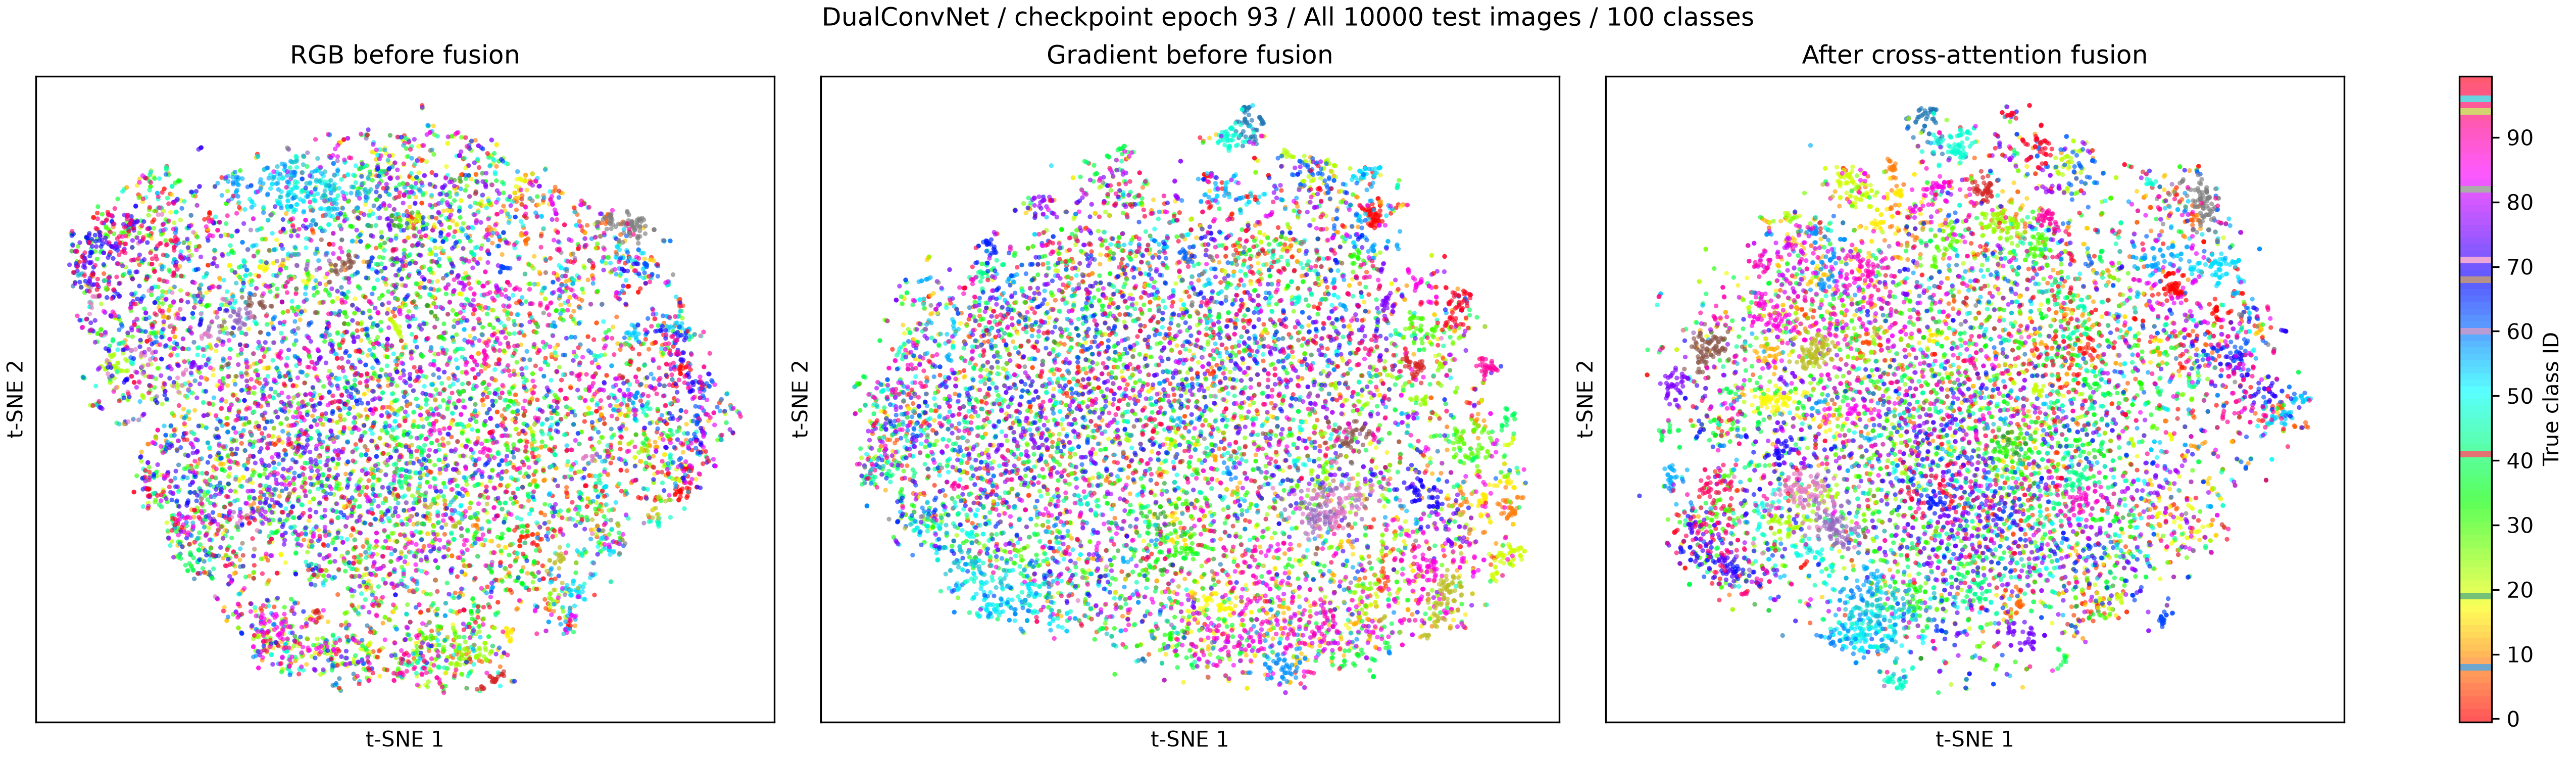

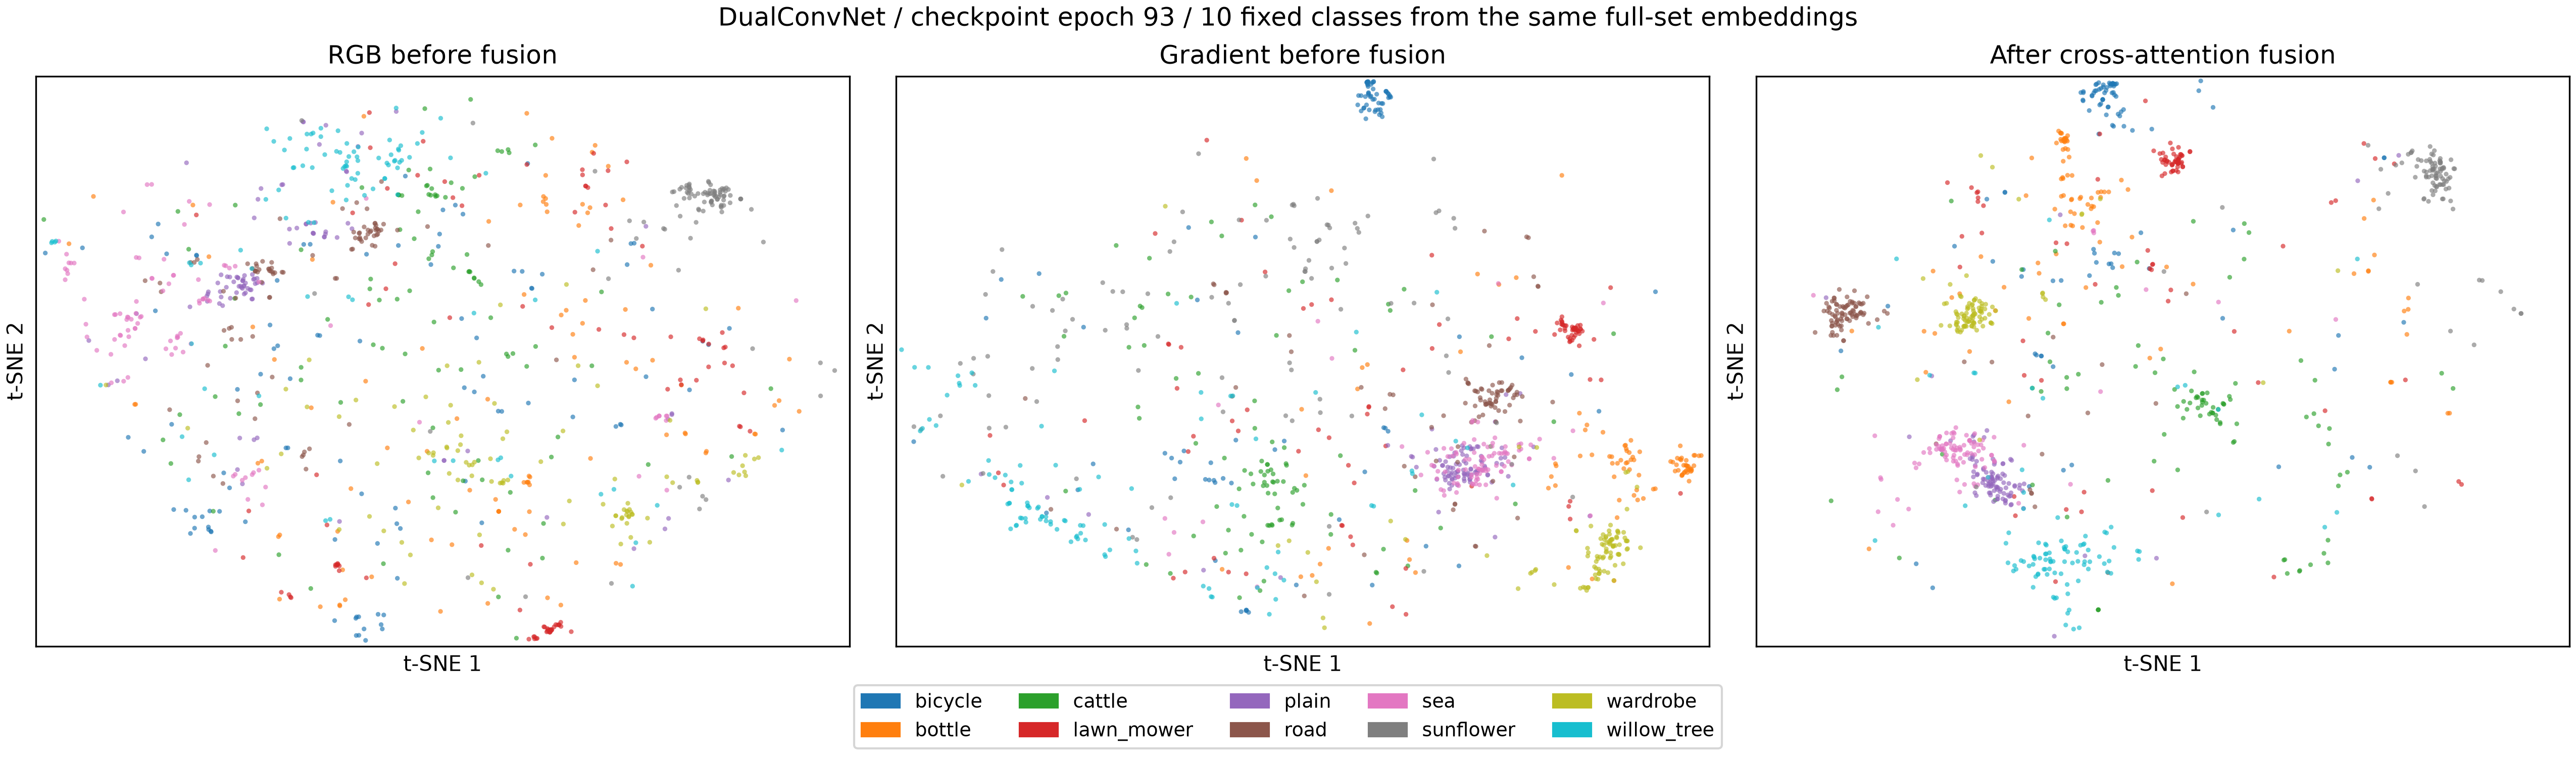

In [ ]:
# Re-run this cell to change t-SNE/plot settings using cached features.
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from threadpoolctl import threadpool_limits

tsne_settings = {
    "n_components": 2, "perplexity": 30, "init": "pca",
    "learning_rate": "auto", "max_iter": 1000,
    "random_state": visualization_seed, "n_jobs": 4,
}


def embed_tsne(values, settings):
    if not 0 < settings["perplexity"] < len(values):
        raise ValueError("perplexity must be positive and smaller than the sample count")
    components = min(50, values.shape[1], len(values) - 1)
    # Limit CPU parallelism on this shared server.
    with threadpool_limits(limits=4):
        reduced = PCA(n_components=components, svd_solver="full").fit_transform(values)
        coordinates = TSNE(**settings).fit_transform(reduced)
    assert coordinates.shape == (len(values), 2)
    assert np.isfinite(coordinates).all()
    return coordinates


with np.load(viz_output_dir / "features.npz", allow_pickle=False) as cached:
    plot_labels = cached["labels"].copy()
    class_names = cached["class_names"].copy()
    source_metadata = json.loads(str(cached["metadata"]))
    plot_features = {name: cached[name].copy() for name in viz_layers}
print(f"t-SNE source: epoch {source_metadata['checkpoint_epoch']}, "
      f"{len(plot_labels)} test images")
tsne_coordinates = {}
for name, values in plot_features.items():
    started = time.perf_counter()
    tsne_coordinates[name] = embed_tsne(values, tsne_settings)
    print(f"{name}: t-SNE finished in {time.perf_counter() - started:.1f}s")
np.savez_compressed(
    viz_output_dir / "tsne_embeddings.npz", **tsne_coordinates,
    labels=plot_labels, class_names=class_names,
    metadata=json.dumps({"source": source_metadata, "tsne_settings": tsne_settings,
                         "pca_components": min(50, len(plot_labels) - 1, 256)}))

# One fixed color per true class in every panel; labels do not enter t-SNE fitting.
class_colors = plt.get_cmap("hsv")(np.linspace(0, 1, len(class_names), endpoint=False))
available_classes = np.unique(plot_labels)
selected_classes = np.sort(np.random.default_rng(visualization_seed).choice(
    available_classes, size=min(10, len(available_classes)), replace=False))
class_colors[selected_classes] = plt.get_cmap("tab10")(np.arange(len(selected_classes)))
class_cmap = ListedColormap(class_colors)
with open(viz_output_dir / "selected_classes.json", "w") as file:
    json.dump({str(int(c)): str(class_names[c]) for c in selected_classes}, file, indent=2)

for selected_only in (False, True):
    mask = np.isin(plot_labels, selected_classes) if selected_only else np.ones(len(plot_labels), dtype=bool)
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")
    for ax, (name, (_, title)) in zip(axes, viz_layers.items()):
        xy = tsne_coordinates[name][mask]
        points = ax.scatter(
            xy[:, 0], xy[:, 1], c=plot_labels[mask], cmap=class_cmap,
            vmin=-0.5, vmax=len(class_names) - 0.5, s=5, alpha=0.65, linewidths=0)
        ax.set(title=title, xlabel="t-SNE 1", ylabel="t-SNE 2")
        ax.set_xticks([])
        ax.set_yticks([])
        if selected_only:
            # Keep the full-set map limits; this view only hides other classes.
            all_xy = tsne_coordinates[name]
            ax.set_xlim(all_xy[:, 0].min() - 1, all_xy[:, 0].max() + 1)
            ax.set_ylim(all_xy[:, 1].min() - 1, all_xy[:, 1].max() + 1)
    if selected_only:
        legend = [Patch(color=class_colors[c], label=str(class_names[c])) for c in selected_classes]
        fig.legend(handles=legend, loc="outside lower center", ncol=5, fontsize=9)
        view = f"{len(selected_classes)} fixed classes from the same full-set embeddings"
        filename = "tsne_selected_classes"
    else:
        fig.colorbar(points, ax=axes, label="True class ID", ticks=np.arange(0, len(class_names), 10))
        view = f"All {len(plot_labels)} test images / {len(available_classes)} classes"
        filename = "tsne_before_after"
    fig.suptitle(f"DualConvNet / checkpoint epoch {source_metadata['checkpoint_epoch']} / {view}")
    for extension in ("png", "pdf"):
        fig.savefig(viz_output_dir / f"{filename}.{extension}", dpi=300)
    plt.show()
    plt.close(fig)
print(f"Saved features, embeddings and figures to {viz_output_dir}")
print("Panels are fitted independently: compare class organization, not absolute positions or cluster distances.")
